# Real-Time FRB Streaming Classifier Pipeline

**Goal**: Build a compact CNN classifier (<50k params, flatten <500 neurons) that simulates
real-time streaming ingestion of CHIME data, producing a **confidence-vs-time** curve as
frequency channels arrive via dispersive delay.

## Pipeline Overview

1. **Data Inspection** — Explore H5 (CHIME) and PKL (LOFAR RFI) structure
2. **Axis-Correct Extraction** — Handle the (freq, beam, time) layout properly
3. **DM-Based Burst Labeling** — Use metadata DM to find which patches contain the burst
4. **Compact CNN** — FPGA-friendly architecture with aggressive pooling
5. **Streaming Simulation** — Dispersive delay → partial spectrogram → P(FRB) vs time
6. **Export** — Save model for hls4ml synthesis

---
## 0. Setup & Imports

In [1]:
import os
import glob
import h5py
import pickle
import warnings
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.image import resize as tf_resize
from sklearn.model_selection import train_test_split

print(f"TensorFlow: {tf.__version__}")
print(f"NumPy: {np.__version__}")
print("All imports OK")

TensorFlow: 2.20.0
NumPy: 1.26.4
All imports OK


---
## 1. Configuration

**Update the two data paths below.**

Folder structure:
```
your_project/
├── realtime_data/
│   ├── FRBs/
│   │   ├── FRB20181209A_22154974_beamformed.h5
│   │   └── ...
│   └── RFIs/
│       └── LOFAR_Full_RFI_dataset.pkl
└── frb_streaming_pipeline.ipynb   ← THIS NOTEBOOK
```

In [2]:
# ============================================================================
# DATA PATHS — UPDATE THESE
# ============================================================================

FRB_H5_DIR  = "./realtime_data/FRBs/"
RFI_PKL_PATH = "./realtime_data/RFIs/LOFAR_Full_RFI_dataset.pkl"

# ============================================================================
# AXIS CONVENTION (from H5 metadata)
# ============================================================================
# tiedbeam_power axis: ['freq', 'beam', 'time']
# Shape: (611, 2, 112763) = (611 freq, 2 beams, 112763 time steps)
# delta_time: 2.56e-06 seconds per time step
#
# CRITICAL: Previous notebooks treated this as (time, beam, freq) — WRONG.
# We must transpose to get (time, freq) = (112763, 611).

# ============================================================================
# EXTRACTION PARAMETERS
# ============================================================================

# Patch dimensions after extraction:
#   Time: 256 steps from the 112763-long time axis
#   Freq: 256 channels (rebinned from 611, only ~2.4x — very gentle)
PATCH_TIME = 256
PATCH_FREQ = 256
STRIDE_TIME = 128          # 50% overlap in time

USE_BEAM = 0               # which beam (0 or 1)

# CHIME frequency range (MHz)
FREQ_LOW = 400.0
FREQ_HIGH = 800.0

# CNN constraints for FPGA synthesis
MAX_PARAMS = 50_000
MAX_FLATTEN_DIM = 500

# Streaming simulation
N_STREAM_STEPS = 50

# Training
BATCH_SIZE = 32
EPOCHS = 30
VALIDATION_SPLIT = 0.2

print("Configuration:")
print(f"  FRB directory:  {FRB_H5_DIR}")
print(f"  RFI pickle:     {RFI_PKL_PATH}")
print(f"  Patch shape:    {PATCH_TIME} time x {PATCH_FREQ} freq")
print(f"  Axis order:     (freq=611, beam=2, time=112763) -> transpose to (time, freq)")
print(f"  Freq rebin:     611 -> {PATCH_FREQ} (~2.4x, very gentle)")
print(f"  FPGA limits:    <{MAX_PARAMS} params, flatten <{MAX_FLATTEN_DIM}")

Configuration:
  FRB directory:  ./realtime_data/FRBs/
  RFI pickle:     ./realtime_data/RFIs/LOFAR_Full_RFI_dataset.pkl
  Patch shape:    256 time x 256 freq
  Axis order:     (freq=611, beam=2, time=112763) -> transpose to (time, freq)
  Freq rebin:     611 -> 256 (~2.4x, very gentle)
  FPGA limits:    <50000 params, flatten <500


---
# Part 1: FRB Data — Load, Inspect, Extract

## 1.1 Discover H5 Files

In [3]:
h5_files = sorted(glob.glob(os.path.join(FRB_H5_DIR, "*.h5")))

print("=" * 80)
print("FRB DATA DISCOVERY")
print("=" * 80)
print(f"\nFound {len(h5_files)} H5 files")

if len(h5_files) == 0:
    print(f"\nNo H5 files found! Check path: {os.path.abspath(FRB_H5_DIR)}")
else:
    for i, f in enumerate(h5_files[:5]):
        file_size_gb = os.path.getsize(f) / (1024**3)
        print(f"  {i+1}. {Path(f).name} ({file_size_gb:.2f} GB)")
    if len(h5_files) > 5:
        print(f"  ... and {len(h5_files) - 5} more")

FRB DATA DISCOVERY

Found 31 H5 files
  1. FRB20181209A_22154974_beamformed.h5 (1.53 GB)
  2. FRB20181213A_22310619_beamformed.h5 (1.52 GB)
  3. FRB20181226E_23948798_beamformed.h5 (0.66 GB)
  4. FRB20181231A_24342210_beamformed.h5 (0.93 GB)
  5. FRB20181231C_24366209_beamformed.h5 (0.14 GB)
  ... and 26 more


## 1.2 Inspect First H5 File — Verify Axes & Metadata

In [4]:
if h5_files:
    with h5py.File(h5_files[0], 'r') as f:
        print(f"File: {Path(h5_files[0]).name}")

        # Top-level attrs
        print(f"\nTop-level attributes:")
        for k in ['event_id', 'event_date', 'delta_time']:
            if k in f.attrs:
                print(f"  {k}: {f.attrs[k]}")

        # tiedbeam_power attrs (contains DM!)
        if 'tiedbeam_power' in f:
            tp = f['tiedbeam_power']
            print(f"\ntiedbeam_power:")
            print(f"  shape: {tp.shape}")
            print(f"  axis:  {tp.attrs.get('axis', 'N/A')}")
            print(f"  DM_coherent: {tp.attrs.get('DM_coherent', 'N/A')}")

            # Peek at data with CORRECT axis interpretation
            # Shape is (freq, beam, time) — we want (time, freq)
            sample = np.array(tp[:, USE_BEAM, :1000], dtype=np.float32)
            sample_T = sample.T  # now (time=1000, freq=611)
            nan_pct = 100.0 * np.isnan(sample_T).sum() / sample_T.size
            print(f"\n  After transpose to (time, freq): {sample_T.shape}")
            print(f"  NaN%: {nan_pct:.1f}%")
            valid = sample_T[~np.isnan(sample_T)]
            if len(valid) > 0:
                print(f"  Range: [{valid.min():.2e}, {valid.max():.2e}]")

        # Check index_map for freq/time arrays
        if 'index_map/freq' in f:
            freq_map = f['index_map/freq'][:]
            print(f"\nindex_map/freq: shape={freq_map.shape}, dtype={freq_map.dtype}")
            if freq_map.dtype.names:
                print(f"  fields: {freq_map.dtype.names}")
                # Often structured with 'centre' field
                if 'centre' in freq_map.dtype.names:
                    centres = freq_map['centre']
                    print(f"  freq range: {centres.min():.1f} - {centres.max():.1f} MHz")

        if 'index_map/time' in f:
            time_map = f['index_map/time'][:]
            print(f"\nindex_map/time: shape={time_map.shape}, dtype={time_map.dtype}")
            if time_map.dtype.names:
                print(f"  fields: {time_map.dtype.names}")

File: FRB20181209A_22154974_beamformed.h5

Top-level attributes:
  event_id: 22154974
  event_date: 2018-12-09T 09:24:51.814410
  delta_time: 2.56e-06

tiedbeam_power:
  shape: (903, 2, 75913)
  axis:  ['freq' 'beam' 'time']
  DM_coherent: 328.6067179471076

  After transpose to (time, freq): (1000, 903)
  NaN%: 0.0%
  Range: [7.47e+01, 1.07e+09]

index_map/freq: shape=(903,), dtype=[('centre', '<f8'), ('id', '<u4')]
  fields: ('centre', 'id')
  freq range: 400.8 - 799.6 MHz

index_map/time: shape=(75913,), dtype=[('offset_fpga', '<u8'), ('offset_s', '<f8')]
  fields: ('offset_fpga', 'offset_s')


## 1.3 Channel Quality Analysis

Same masking as before, but now applied to the **611 frequency channels** (axis 0).

Channel quality (903 freq channels):
  Good:      896
  NaN-bad:   0
  Zero-var:  0
  Outlier:   7
  Usable:    99.2%


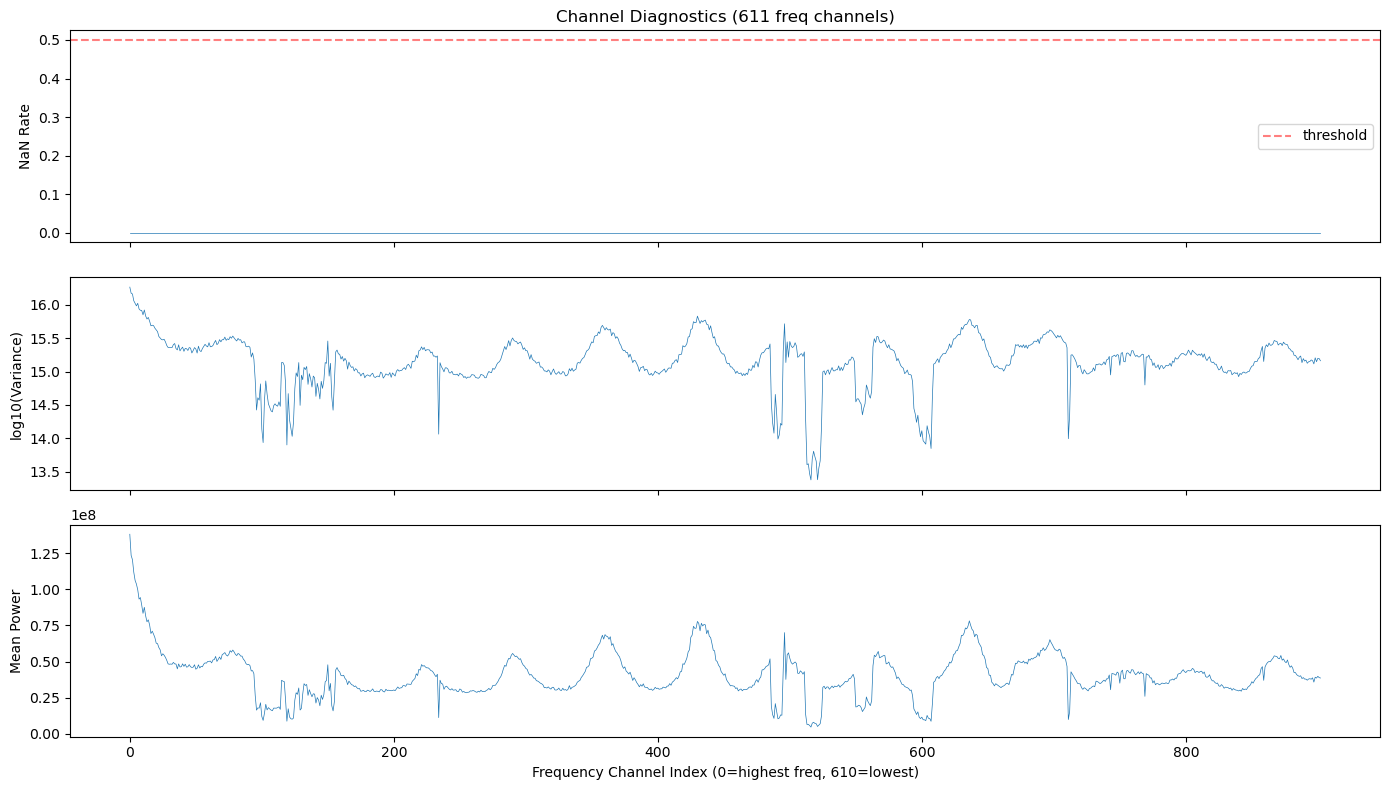

In [6]:
def analyze_channels(h5_path, use_beam=0, n_time_sample=2000):
    """
    Analyze channel quality. Loads a time chunk and checks each freq channel.
    AXIS-CORRECTED: shape is (freq, beam, time).
    """
    with h5py.File(h5_path, 'r') as f:
        tp = f['tiedbeam_power']
        n_freq, n_beam, n_time = tp.shape
        n_t = min(n_time_sample, n_time)
        # Load (freq, beam=use_beam, time[:n_t]) then transpose to (time, freq)
        raw = np.array(tp[:, use_beam, :n_t], dtype=np.float32)  # (611, n_t)
        sample = raw.T  # (n_t, 611) = (time, freq)

    n_freq = sample.shape[1]

    # NaN rate per channel
    nan_rate = np.isnan(sample).mean(axis=0)
    nan_bad = nan_rate > 0.5

    # Variance per channel
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        chan_var = np.nanvar(sample, axis=0)
        chan_mean = np.nanmean(sample, axis=0)
    chan_var = np.nan_to_num(chan_var, nan=0.0)
    chan_mean = np.nan_to_num(chan_mean, nan=0.0)
    var_bad = chan_var < 1e-10

    # Outlier detection (MAD-based)
    valid_means = chan_mean[~nan_bad & ~var_bad]
    if len(valid_means) > 10:
        med = np.median(valid_means)
        mad = np.median(np.abs(valid_means - med))
        if mad > 0:
            z = np.abs(chan_mean - med) / (1.4826 * mad)
            outlier_bad = z > 5.0
        else:
            outlier_bad = np.zeros(n_freq, dtype=bool)
    else:
        outlier_bad = np.zeros(n_freq, dtype=bool)

    mask = ~(nan_bad | var_bad | outlier_bad)
    diag = {
        "total": n_freq, "good": mask.sum(),
        "nan_flagged": nan_bad.sum(), "var_flagged": var_bad.sum(),
        "outlier_flagged": outlier_bad.sum(),
        "nan_rate": nan_rate, "chan_var": chan_var, "chan_mean": chan_mean,
    }
    return mask, diag


if h5_files:
    chan_mask, chan_diag = analyze_channels(h5_files[0], use_beam=USE_BEAM)

    print(f"Channel quality ({chan_diag['total']} freq channels):")
    print(f"  Good:      {chan_diag['good']}")
    print(f"  NaN-bad:   {chan_diag['nan_flagged']}")
    print(f"  Zero-var:  {chan_diag['var_flagged']}")
    print(f"  Outlier:   {chan_diag['outlier_flagged']}")
    pct = 100 * chan_diag['good'] / chan_diag['total']
    print(f"  Usable:    {pct:.1f}%")

    fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
    axes[0].plot(chan_diag["nan_rate"], lw=0.5)
    axes[0].set_ylabel("NaN Rate")
    axes[0].set_title("Channel Diagnostics (611 freq channels)")
    axes[0].axhline(0.5, color="r", ls="--", alpha=0.5, label="threshold")
    axes[0].legend()

    axes[1].plot(np.log10(chan_diag["chan_var"] + 1e-20), lw=0.5)
    axes[1].set_ylabel("log10(Variance)")

    axes[2].plot(chan_diag["chan_mean"], lw=0.5)
    axes[2].set_ylabel("Mean Power")
    axes[2].set_xlabel("Frequency Channel Index (0=highest freq, 610=lowest)")

    plt.tight_layout()
    plt.show()

## 1.4 Extraction Functions — Axis-Corrected + DM-Based Labeling

**Key fixes:**
- Axis order: `(freq=611, beam=2, time=112763)` → transpose to `(time, freq)`
- Freq rebin: 611 → 256 (only ~2.4x — **much** gentler than the old 1760x)
- DM from metadata: compute which time bins contain the burst for labeling
- Channel removal before rebinning

In [7]:
def load_frb_file(h5_path, use_beam=0, channel_mask=None):
    """
    Load an FRB H5 file with CORRECT axis handling.

    H5 layout: tiedbeam_power shape = (freq=611, beam=2, time=112763)
    We transpose to (time, freq) and apply channel masking.

    Returns:
        spectrum: (n_time, n_clean_freq) array
        dm: DM_coherent from metadata
        delta_t: time step in seconds
        metadata: dict
    """
    with h5py.File(h5_path, 'r') as f:
        tp = f['tiedbeam_power']
        raw = tp[:, use_beam, :]           # (611, 112763) = (freq, time)
        spectrum = raw.T.astype(np.float32)  # (112763, 611) = (time, freq)

        dm = tp.attrs.get('DM_coherent', None)
        delta_t = f.attrs.get('delta_time', 2.56e-6)
        event_id = f.attrs.get('event_id', 'unknown')

    n_time, n_freq_orig = spectrum.shape

    # Apply channel mask (remove bad freq channels)
    if channel_mask is None:
        nan_per_freq = np.isnan(spectrum).sum(axis=0)
        channel_mask = nan_per_freq < (n_time * 0.5)

    n_masked = (~channel_mask).sum()
    spectrum = spectrum[:, channel_mask]

    # Fill remaining NaN with per-channel median
    if np.isnan(spectrum).any():
        for ch in range(spectrum.shape[1]):
            col = spectrum[:, ch]
            nans = np.isnan(col)
            if nans.any() and not nans.all():
                col[nans] = np.nanmedian(col)
            elif nans.all():
                col[:] = 0.0

    metadata = {
        'filename': Path(h5_path).name,
        'event_id': event_id,
        'dm': dm,
        'delta_t': delta_t,
        'n_time': n_time,
        'n_freq_original': n_freq_orig,
        'n_freq_clean': spectrum.shape[1],
        'n_freq_masked': int(n_masked),
        'total_duration_ms': n_time * delta_t * 1000,
    }
    return spectrum, metadata


def compute_burst_time_range(n_freq_clean, dm, delta_t,
                             freq_low=FREQ_LOW, freq_high=FREQ_HIGH,
                             margin_factor=1.5):
    """
    Compute the time range (in sample indices) where the burst occurs.
    Uses the DM to calculate dispersive delay.

    Returns:
        burst_start: first time index where burst arrives (highest freq)
        burst_end: last time index (lowest freq)
        burst_duration_samples: total duration of sweep
    """
    # Dispersive delay at lowest freq relative to highest
    delay_ms = 4.149 * dm * (freq_low**(-2) - freq_high**(-2))
    delay_samples = int(delay_ms * 1e-3 / delta_t)

    # Add margin for pulse width and scattering
    margin = int(delay_samples * margin_factor)

    return delay_samples, margin


def rebin_freq(spectrum, target_freq):
    """Rebin frequency axis from n_freq -> target_freq by averaging."""
    n_time, n_freq = spectrum.shape
    factor = max(1, n_freq // target_freq)
    if factor <= 1:
        return spectrum[:, :target_freq] if n_freq >= target_freq else spectrum

    freq_bins = n_freq // factor
    trimmed = spectrum[:, :freq_bins * factor]
    rebinned = trimmed.reshape(n_time, freq_bins, factor).mean(axis=2)

    # Resize to exact target if needed
    if rebinned.shape[1] != target_freq:
        rebinned = tf_resize(
            rebinned[..., np.newaxis], (n_time, target_freq)
        ).numpy()[:, :, 0]

    return rebinned


def extract_labeled_patches(spectrum, metadata, channel_mask=None,
                            patch_time=PATCH_TIME, patch_freq=PATCH_FREQ,
                            stride=STRIDE_TIME):
    """
    Extract patches and label them using DM-based burst location.

    Patches overlapping the burst time range -> label 1 (FRB+)
    All other patches -> label 0 (FRB-, real telescope noise)

    Returns:
        patches: list of (patch_time, patch_freq, 1) arrays
        labels: list of 0/1
        positions: list of (start_t, end_t)
    """
    n_time, n_freq = spectrum.shape
    dm = metadata.get('dm', None)
    delta_t = metadata.get('delta_t', 2.56e-6)

    # Rebin frequency
    spec_rb = rebin_freq(spectrum, patch_freq)

    # Per-channel normalization
    mean = np.mean(spec_rb, axis=0, keepdims=True)
    std = np.std(spec_rb, axis=0, keepdims=True)
    std[std < 1e-10] = 1.0
    spec_rb = (spec_rb - mean) / std

    patches = []
    labels = []
    positions = []

    # Compute burst location if DM is available
    if dm is not None:
        delay_ms = 4.149 * dm * (FREQ_LOW**(-2) - FREQ_HIGH**(-2))
        delay_samples = int(delay_ms * 1e-3 / delta_t)

        # The burst is centered somewhere in the observation.
        # For CHIME triggered data, the burst is typically near the middle.
        # We detect it by looking for peak power in the dedispersed time series.
        # Simple approach: sum power along the expected DM track
        col_power = np.nanmean(np.abs(spec_rb), axis=1)  # power vs time
        # Smooth to find the envelope
        kernel_size = max(1, delay_samples // 10)
        if kernel_size > 1:
            kernel = np.ones(kernel_size) / kernel_size
            col_power_smooth = np.convolve(col_power, kernel, mode='same')
        else:
            col_power_smooth = col_power

        burst_center = np.argmax(col_power_smooth)
        burst_start = max(0, burst_center - delay_samples)
        burst_end = min(n_time, burst_center + delay_samples)
        print(f"    DM={dm:.1f} -> sweep={delay_ms:.1f}ms ({delay_samples} samples) "
              f"-> burst at t=[{burst_start}, {burst_end}]")
    else:
        burst_start = None
        burst_end = None
        print(f"    No DM metadata — all patches labeled FRB+")

    # Sliding window
    for start_t in range(0, n_time - patch_time + 1, stride):
        end_t = start_t + patch_time
        window = spec_rb[start_t:end_t, :]

        if window.shape != (patch_time, patch_freq):
            window = tf_resize(
                window[..., np.newaxis], (patch_time, patch_freq)
            ).numpy()
        else:
            window = window[..., np.newaxis]

        patches.append(window)
        positions.append((start_t, end_t))

        # Label based on overlap with burst
        if burst_start is not None:
            overlaps = (start_t < burst_end) and (end_t > burst_start)
            labels.append(1 if overlaps else 0)
        else:
            labels.append(1)  # fallback: all positive

    return patches, labels, positions


print("Extraction functions defined (axis-corrected)")

Extraction functions defined (axis-corrected)


## 1.5 Extract FRB Patches from All Files

This processes each H5 file:
1. Loads with correct (freq, beam, time) → (time, freq) transpose
2. Removes bad frequency channels
3. Rebins 611 → 256 freq channels (~2.4x — gentle)
4. Uses DM to label burst vs noise patches

In [8]:
print("=" * 80)
print(f"EXTRACTING FRB PATCHES FROM {len(h5_files)} FILES")
print(f"  Axes: (freq, beam, time) -> transpose -> (time={112763}, freq={611})")
print(f"  Patch: {PATCH_TIME}t x {PATCH_FREQ}f | Stride: {STRIDE_TIME} | Beam: {USE_BEAM}")
print("=" * 80)
print()

all_frb_patches = []
all_frb_labels = []
all_frb_meta = []

# Build channel mask from first file
if h5_files:
    global_chan_mask, _ = analyze_channels(h5_files[0], use_beam=USE_BEAM)

for i, h5_path in enumerate(h5_files):
    fname = Path(h5_path).name
    print(f"[{i+1:2d}/{len(h5_files)}] {fname:50s}")

    try:
        spectrum, file_meta = load_frb_file(
            h5_path, use_beam=USE_BEAM, channel_mask=global_chan_mask
        )
        dur = file_meta['total_duration_ms']
        nf = file_meta['n_freq_clean']
        print(f"    shape: ({spectrum.shape[0]}, {nf}) = (time, freq)  "
              f"duration: {dur:.1f} ms  masked: {file_meta['n_freq_masked']}")

        patches, labels, positions = extract_labeled_patches(spectrum, file_meta)

        n_pos = sum(labels)
        n_neg = len(labels) - n_pos
        print(f"    -> {len(patches)} patches ({n_pos} FRB+, {n_neg} FRB-)")

        for patch, label, (st, et) in zip(patches, labels, positions):
            all_frb_patches.append(patch)
            all_frb_labels.append(label)
            all_frb_meta.append({**file_meta, 'time_range': (int(st), int(et))})

    except Exception as e:
        print(f"    ERROR: {e}")
        import traceback; traceback.print_exc()
        continue

if all_frb_patches:
    frb_samples = np.array(all_frb_patches, dtype=np.float32)
    frb_labels = np.array(all_frb_labels, dtype=int)

    print(f"\n{'=' * 80}")
    print("FRB EXTRACTION COMPLETE")
    print(f"{'=' * 80}")
    print(f"Total patches:  {len(frb_samples):,}")
    print(f"Shape:          {frb_samples.shape}")
    print(f"FRB+ (burst):   {(frb_labels == 1).sum()}")
    print(f"FRB- (noise):   {(frb_labels == 0).sum()}")
    print(f"NaN remaining:  {np.isnan(frb_samples).sum()}")
else:
    print("\nNo patches extracted. Check data paths.")
    frb_samples = np.array([])
    frb_labels = np.array([])

EXTRACTING FRB PATCHES FROM 31 FILES
  Axes: (freq, beam, time) -> transpose -> (time=112763, freq=611)
  Patch: 256t x 256f | Stride: 128 | Beam: 0

[ 1/31] FRB20181209A_22154974_beamformed.h5               
    shape: (75913, 896) = (time, freq)  duration: 194.3 ms  masked: 7
    DM=328.6 -> sweep=0.0ms (2 samples) -> burst at t=[28369, 28373]
    -> 592 patches (2 FRB+, 590 FRB-)
[ 2/31] FRB20181213A_22310619_beamformed.h5               
    ERROR: boolean index did not match indexed array along dimension 1; dimension is 895 but corresponding boolean dimension is 903
[ 3/31] FRB20181226E_23948798_beamformed.h5               
    ERROR: boolean index did not match indexed array along dimension 1; dimension is 348 but corresponding boolean dimension is 903
[ 4/31] FRB20181231A_24342210_beamformed.h5               


Traceback (most recent call last):
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\4117354245.py", line 21, in <module>
    spectrum, file_meta = load_frb_file(
                          ^^^^^^^^^^^^^^
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\2791519574.py", line 31, in load_frb_file
    spectrum = spectrum[:, channel_mask]
               ~~~~~~~~^^^^^^^^^^^^^^^^^
IndexError: boolean index did not match indexed array along dimension 1; dimension is 895 but corresponding boolean dimension is 903
Traceback (most recent call last):
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\4117354245.py", line 21, in <module>
    spectrum, file_meta = load_frb_file(
                          ^^^^^^^^^^^^^^
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\2791519574.py", line 31, in load_frb_file
    spectrum = spectrum[:, channel_mask]
               ~~~~~~~~^^^^^^^^^^^^^^^^^
IndexError: boolean index did not match indexed array along dimension 1; dimens

    ERROR: boolean index did not match indexed array along dimension 1; dimension is 446 but corresponding boolean dimension is 903
[ 5/31] FRB20181231C_24366209_beamformed.h5               
    ERROR: boolean index did not match indexed array along dimension 1; dimension is 108 but corresponding boolean dimension is 903
[ 6/31] FRB20190102A_24510924_beamformed.h5               
    ERROR: boolean index did not match indexed array along dimension 1; dimension is 168 but corresponding boolean dimension is 903
[ 7/31] FRB20190103C_24644651_beamformed.h5               
    ERROR: boolean index did not match indexed array along dimension 1; dimension is 317 but corresponding boolean dimension is 903
[ 8/31] FRB20190210B_30105124_beamformed.h5               
    ERROR: boolean index did not match indexed array along dimension 1; dimension is 289 but corresponding boolean dimension is 903
[ 9/31] FRB20190213D_30502098_beamformed.h5               
    ERROR: boolean index did not match indexe

Traceback (most recent call last):
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\4117354245.py", line 21, in <module>
    spectrum, file_meta = load_frb_file(
                          ^^^^^^^^^^^^^^
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\2791519574.py", line 31, in load_frb_file
    spectrum = spectrum[:, channel_mask]
               ~~~~~~~~^^^^^^^^^^^^^^^^^
IndexError: boolean index did not match indexed array along dimension 1; dimension is 317 but corresponding boolean dimension is 903
Traceback (most recent call last):
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\4117354245.py", line 21, in <module>
    spectrum, file_meta = load_frb_file(
                          ^^^^^^^^^^^^^^
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\2791519574.py", line 31, in load_frb_file
    spectrum = spectrum[:, channel_mask]
               ~~~~~~~~^^^^^^^^^^^^^^^^^
IndexError: boolean index did not match indexed array along dimension 1; dimens

    ERROR: boolean index did not match indexed array along dimension 1; dimension is 551 but corresponding boolean dimension is 903
[11/31] FRB20190304B_32415255_beamformed.h5               
    ERROR: boolean index did not match indexed array along dimension 1; dimension is 368 but corresponding boolean dimension is 903
[12/31] FRB20190405B_35579228_beamformed.h5               
    ERROR: boolean index did not match indexed array along dimension 1; dimension is 664 but corresponding boolean dimension is 903
[13/31] FRB20190410B_36154661_beamformed.h5               
    ERROR: Unable to synchronously open file (truncated file: eof = 455081984, sblock->base_addr = 0, stored_eof = 1035613644)
[14/31] FRB20190420B_37342401_beamformed.h5               


...

Traceback (most recent call last):
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\4117354245.py", line 21, in <module>
    spectrum, file_meta = load_frb_file(
                          ^^^^^^^^^^^^^^
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\2791519574.py", line 31, in load_frb_file
    spectrum = spectrum[:, channel_mask]
               ~~~~~~~~^^^^^^^^^^^^^^^^^
IndexError: boolean index did not match indexed array along dimension 1; dimension is 611 but corresponding boolean dimension is 903
Traceback (most recent call last):
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\4117354245.py", line 21, in <module>
    spectrum, file_meta = load_frb_file(
                          ^^^^^^^^^^^^^^
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\2791519574.py", line 31, in load_frb_file
    spectrum = spectrum[:, channel_mask]
               ~~~~~~~~^^^^^^^^^^^^^^^^^
IndexError: boolean index did not match indexed array along dimension 1; dimens

    ERROR: boolean index did not match indexed array along dimension 1; dimension is 783 but corresponding boolean dimension is 903
[28/31] FRB20190627A_42608900_beamformed.h5               
    ERROR: boolean index did not match indexed array along dimension 1; dimension is 181 but corresponding boolean dimension is 903
[29/31] FRB20190627D_42637411_beamformed.h5               
    ERROR: boolean index did not match indexed array along dimension 1; dimension is 193 but corresponding boolean dimension is 903
[30/31] FRB20190628C_42842438_beamformed.h5               
    ERROR: boolean index did not match indexed array along dimension 1; dimension is 283 but corresponding boolean dimension is 903
[31/31] FRB20190630C_43098433_beamformed.h5               


Traceback (most recent call last):
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\4117354245.py", line 21, in <module>
    spectrum, file_meta = load_frb_file(
                          ^^^^^^^^^^^^^^
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\2791519574.py", line 31, in load_frb_file
    spectrum = spectrum[:, channel_mask]
               ~~~~~~~~^^^^^^^^^^^^^^^^^
IndexError: boolean index did not match indexed array along dimension 1; dimension is 783 but corresponding boolean dimension is 903
Traceback (most recent call last):
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\4117354245.py", line 21, in <module>
    spectrum, file_meta = load_frb_file(
                          ^^^^^^^^^^^^^^
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\2791519574.py", line 31, in load_frb_file
    spectrum = spectrum[:, channel_mask]
               ~~~~~~~~^^^^^^^^^^^^^^^^^
IndexError: boolean index did not match indexed array along dimension 1; dimens

    ERROR: boolean index did not match indexed array along dimension 1; dimension is 325 but corresponding boolean dimension is 903

FRB EXTRACTION COMPLETE
Total patches:  592
Shape:          (592, 256, 256, 1)
FRB+ (burst):   2
FRB- (noise):   590
NaN remaining:  0


Traceback (most recent call last):
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\4117354245.py", line 21, in <module>
    spectrum, file_meta = load_frb_file(
                          ^^^^^^^^^^^^^^
  File "C:\Users\tobys\AppData\Local\Temp\ipykernel_28224\2791519574.py", line 31, in load_frb_file
    spectrum = spectrum[:, channel_mask]
               ~~~~~~~~^^^^^^^^^^^^^^^^^
IndexError: boolean index did not match indexed array along dimension 1; dimension is 325 but corresponding boolean dimension is 903


## 1.6 Visualize: Burst vs Noise Patches

Top row: FRB+ patches (contain burst). Bottom row: FRB- patches (noise only).
You should see dispersive sweeps ONLY in the top row.

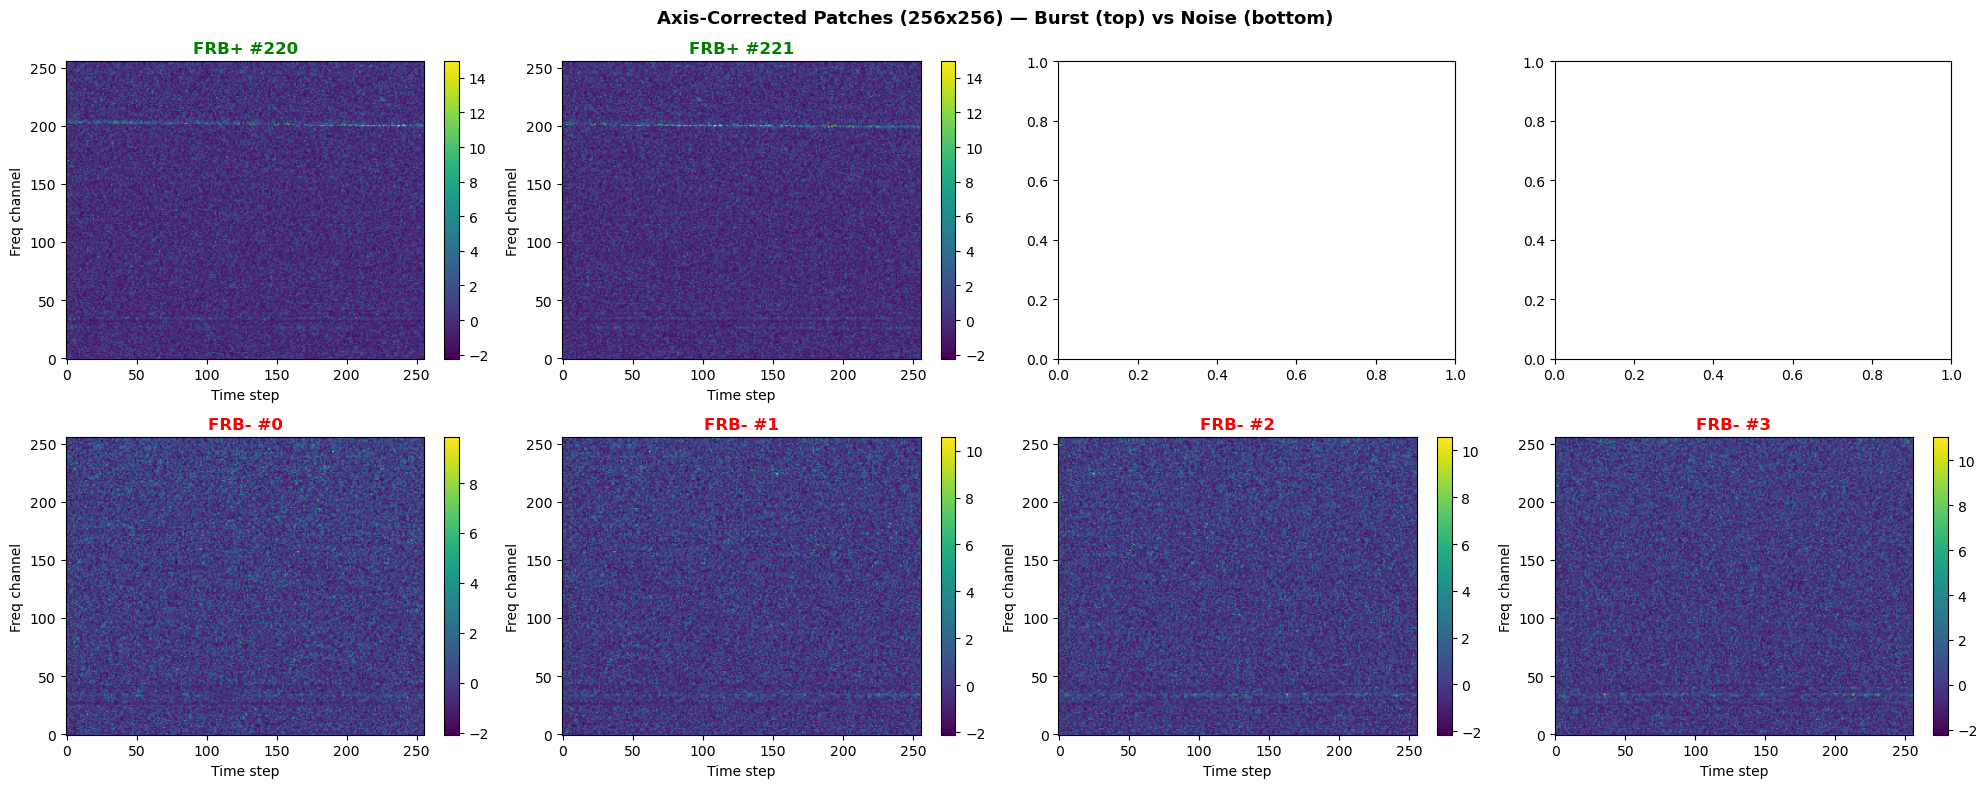

In [9]:
if len(frb_samples) > 0:
    pos_idx = np.where(frb_labels == 1)[0]
    neg_idx = np.where(frb_labels == 0)[0]

    fig, axes = plt.subplots(2, 4, figsize=(20, 8))

    # Top: FRB+ patches
    show_pos = pos_idx[:4] if len(pos_idx) >= 4 else pos_idx
    for i, idx in enumerate(show_pos):
        ax = axes[0, i]
        im = ax.imshow(frb_samples[idx, :, :, 0].T, aspect='auto',
                       origin='lower', cmap='viridis')
        ax.set_title(f'FRB+ #{idx}', color='green', fontweight='bold')
        ax.set_xlabel('Time step')
        ax.set_ylabel('Freq channel')
        plt.colorbar(im, ax=ax, fraction=0.046)

    # Bottom: FRB- patches
    show_neg = neg_idx[:4] if len(neg_idx) >= 4 else neg_idx
    for i, idx in enumerate(show_neg):
        ax = axes[1, i]
        im = ax.imshow(frb_samples[idx, :, :, 0].T, aspect='auto',
                       origin='lower', cmap='viridis')
        ax.set_title(f'FRB- #{idx}', color='red', fontweight='bold')
        ax.set_xlabel('Time step')
        ax.set_ylabel('Freq channel')
        plt.colorbar(im, ax=ax, fraction=0.046)

    plt.suptitle(
        f'Axis-Corrected Patches ({PATCH_TIME}x{PATCH_FREQ}) — '
        f'Burst (top) vs Noise (bottom)',
        fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("No patches to visualize.")

---
# Part 2: RFI Data — Load, Inspect, Extract

## 2.1 Load & Inspect RFI Pickle

In [ ]:
print("=" * 80)
print("RFI DATA LOADING")
print("=" * 80)
print(f"\nLoading: {RFI_PKL_PATH}")

if not os.path.exists(RFI_PKL_PATH):
    print(f"\nFile not found: {os.path.abspath(RFI_PKL_PATH)}")
    rfi_list = None
else:
    file_size_mb = os.path.getsize(RFI_PKL_PATH) / (1024**2)
    print(f"File size: {file_size_mb:.1f} MB")

    with open(RFI_PKL_PATH, 'rb') as f:
        rfi_list = pickle.load(f)

    print(f"Loaded: {type(rfi_list).__name__} with {len(rfi_list)} elements")
    print(f"\nElement inspection:")
    for i, elem in enumerate(rfi_list):
        if isinstance(elem, np.ndarray):
            is_mask = elem.dtype == bool
            elem_type = "Boolean mask" if is_mask else "Data array"
            print(f"  [{i}] {elem_type:15s} shape={str(elem.shape):25s} dtype={elem.dtype}")
            if not is_mask:
                print(f"       Range: [{elem.min():.2e}, {elem.max():.2e}]")

## 2.2 Separate Data from Masks

In [ ]:
rfi_data_arrays = []
rfi_mask_arrays = []

if rfi_list is not None:
    for elem in rfi_list:
        if isinstance(elem, np.ndarray):
            if elem.dtype == bool:
                rfi_mask_arrays.append(elem)
            else:
                rfi_data_arrays.append(elem)

    print(f"Found {len(rfi_data_arrays)} data arrays")
    print(f"Found {len(rfi_mask_arrays)} mask arrays")
    for i, arr in enumerate(rfi_data_arrays):
        print(f"  Data {i}: {arr.shape}")
    for i, arr in enumerate(rfi_mask_arrays):
        print(f"  Mask {i}: {arr.shape}")
else:
    print("No RFI data loaded.")

## 2.3 Extract RFI Patches

In [ ]:
def extract_rfi_patches(rfi_array, mask=None,
                        patch_time=PATCH_TIME, patch_freq=PATCH_FREQ,
                        stride=STRIDE_TIME, max_samples=None):
    """Extract patches from RFI 4D array (N, time, freq, 1)."""
    if rfi_array.ndim == 4:
        n_spectra, n_time, n_freq, _ = rfi_array.shape
    elif rfi_array.ndim == 3:
        n_spectra, n_time, n_freq = rfi_array.shape
    elif rfi_array.ndim == 2:
        rfi_array = rfi_array[np.newaxis, ..., np.newaxis]
        n_spectra, n_time, n_freq, _ = rfi_array.shape
    else:
        print(f"  Unexpected shape: {rfi_array.shape}")
        return []

    target_shape = (patch_time, patch_freq)
    patches = []

    for spec_idx in range(n_spectra):
        if rfi_array.ndim == 4:
            spectrum = rfi_array[spec_idx, :, :, 0].copy()
        else:
            spectrum = rfi_array[spec_idx, :, :].copy()

        if mask is not None:
            if mask.ndim == 4:
                spec_mask = mask[spec_idx, :, :, 0]
            elif mask.ndim == 3:
                spec_mask = mask[spec_idx, :, :]
            else:
                spec_mask = mask
            spectrum[spec_mask] = 0.0

        spectrum = np.nan_to_num(spectrum, nan=0.0)

        # Per-channel normalize
        mean = np.mean(spectrum, axis=0, keepdims=True)
        std = np.std(spectrum, axis=0, keepdims=True)
        std[std < 1e-10] = 1.0
        spectrum = (spectrum - mean) / std

        for start_t in range(0, n_time - patch_time + 1, stride):
            end_t = start_t + patch_time
            window = spectrum[start_t:end_t, :]

            if window.shape != target_shape:
                window = tf_resize(
                    window[..., np.newaxis], target_shape
                ).numpy()
            else:
                window = window[..., np.newaxis]

            patches.append(window)
            if max_samples and len(patches) >= max_samples:
                return patches

    return patches

print("RFI extraction function defined")

## 2.4 Extract RFI Patches (Balanced)

In [ ]:
if rfi_data_arrays and len(frb_samples) > 0:
    # Target: match total FRB- count (noise + rfi should be balanced with FRB+)
    n_frb_pos = int((frb_labels == 1).sum())
    n_frb_neg = int((frb_labels == 0).sum())

    # We want roughly equal FRB+ and FRB- in the final dataset
    # FRB- already has n_frb_neg noise patches. Add RFI to bring total negatives up
    # or just extract a reasonable amount of RFI
    target_n_rfi = max(n_frb_pos, n_frb_neg)
    n_arrays = len(rfi_data_arrays)
    samples_per_array = target_n_rfi // n_arrays if n_arrays > 0 else target_n_rfi

    print("=" * 80)
    print(f"EXTRACTING RFI PATCHES (Target: ~{target_n_rfi})")
    print("=" * 80)

    all_rfi_patches = []
    for i, data_array in enumerate(rfi_data_arrays):
        print(f"Array {i+1}/{n_arrays}: shape={data_array.shape}", end="")
        arr_mask = rfi_mask_arrays[i] if i < len(rfi_mask_arrays) else None
        patches = extract_rfi_patches(data_array, mask=arr_mask, max_samples=samples_per_array)
        all_rfi_patches.extend(patches)
        print(f" -> {len(patches)} patches")

    rfi_samples = np.array(all_rfi_patches, dtype=np.float32)

    if len(rfi_samples) > target_n_rfi:
        idx = np.random.choice(len(rfi_samples), target_n_rfi, replace=False)
        rfi_samples = rfi_samples[idx]

    print(f"\nRFI EXTRACTION COMPLETE: {len(rfi_samples):,} patches, shape={rfi_samples.shape}")
else:
    print("Missing data.")
    rfi_samples = np.array([])

## 2.5 Visualize RFI Patches

In [ ]:
if len(rfi_samples) > 0:
    n_show = min(8, len(rfi_samples))
    indices = np.linspace(0, len(rfi_samples) - 1, n_show, dtype=int)

    fig, axes = plt.subplots(2, 4, figsize=(20, 8))
    for i, idx in enumerate(indices):
        ax = axes.ravel()[i]
        im = ax.imshow(rfi_samples[idx, :, :, 0].T, aspect='auto',
                       origin='lower', cmap='viridis')
        ax.set_title(f'RFI Patch {idx}', color='red', fontweight='bold')
        ax.set_xlabel('Time step')
        ax.set_ylabel('Freq channel')
        plt.colorbar(im, ax=ax, fraction=0.046)
    plt.suptitle('RFI Patches', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

---
# Part 3: Build Dataset & Train Compact CNN

## 3.1 Combine Dataset

Three sources of data:
- **FRB+** (burst patches, label=1) — from DM-based labeling
- **FRB-** (noise patches from FRB files, label=0)
- **RFI** (LOFAR interference, label=0)

In [ ]:
if len(frb_samples) > 0 and len(rfi_samples) > 0:
    X = np.concatenate([frb_samples, rfi_samples], axis=0)
    y = np.concatenate([frb_labels, np.zeros(len(rfi_samples))])

    shuffle_idx = np.random.permutation(len(X))
    X = X[shuffle_idx]
    y = y[shuffle_idx]

    n_pos = int(y.sum())
    n_neg = int(len(y) - n_pos)
    print(f"Combined dataset:")
    print(f"  FRB+ (burst):   {n_pos}")
    print(f"  Negative:       {n_neg} ({int((frb_labels==0).sum())} telescope noise + {len(rfi_samples)} RFI)")
    print(f"  Total:          {len(X):,}")
    print(f"  Shape:          {X.shape}")

    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=VALIDATION_SPLIT, stratify=y, random_state=42
    )

    print(f"\nSplit:")
    print(f"  Train: {len(X_train)} ({int((y_train==1).sum())} +, {int((y_train==0).sum())} -)")
    print(f"  Val:   {len(X_val)} ({int((y_val==1).sum())} +, {int((y_val==0).sum())} -)")
else:
    print("Missing data.")

## 3.2 Compact CNN

For input `(256, 256, 1)`:
```
Conv2D(8)  + MaxPool(4,4) -> 64 x 64
Conv2D(16) + MaxPool(4,4) -> 16 x 16
Conv2D(16) + MaxPool(4,4) ->  4 x  4
Flatten: 4 * 4 * 16 = 256 neurons  (under 500 limit)
```

In [ ]:
def build_compact_cnn(input_shape):
    """Compact CNN for FPGA deployment."""
    inp = keras.Input(shape=input_shape, name='input')

    x = layers.Conv2D(8, (3,3), activation='relu', padding='same', name='conv1')(inp)
    x = layers.MaxPooling2D((4, 4), name='pool1')(x)

    x = layers.Conv2D(16, (3,3), activation='relu', padding='same', name='conv2')(x)
    x = layers.MaxPooling2D((4, 4), name='pool2')(x)

    x = layers.Conv2D(16, (3,3), activation='relu', padding='same', name='conv3')(x)
    x = layers.MaxPooling2D((4, 4), name='pool3')(x)

    x = layers.Flatten(name='flatten')(x)
    x = layers.Dense(32, activation='relu', name='dense1')(x)
    x = layers.Dense(1, activation='sigmoid', name='output')(x)

    return keras.Model(inp, x, name='frb_compact_cnn')


input_shape = (PATCH_TIME, PATCH_FREQ, 1)
model = build_compact_cnn(input_shape)
model.summary()

flatten_dim = model.get_layer('flatten').output_shape[-1]
total_params = model.count_params()
print(f"\nFPGA CHECK: flatten={flatten_dim} {'PASS' if flatten_dim <= MAX_FLATTEN_DIM else 'FAIL'}, "
      f"params={total_params:,} {'PASS' if total_params <= MAX_PARAMS else 'FAIL'}")

## 3.3 Train

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

n_pos = int((y_train == 1).sum())
n_neg = int((y_train == 0).sum())
class_weight = {0: 1.0, 1: n_neg / max(n_pos, 1)}
print(f"Class weights: {class_weight}")

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    class_weight=class_weight,
    verbose=1
)

## 3.4 Training Diagnostics

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train')
axes[0].plot(history.history['val_loss'], label='Val')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].set_title('Loss'); axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Train')
axes[1].plot(history.history['val_accuracy'], label='Val')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend(); axes[1].set_title('Accuracy'); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
print(f"\nValidation accuracy: {val_acc:.4f}")
print(f"Validation loss:     {val_loss:.4f}")

---
# Part 4: Streaming Simulation — Confidence vs Time

**Key deliverable.** Simulates how confidence evolves as frequency channels arrive
via dispersive delay. High frequencies arrive first, low frequencies last.

> dt = 4.149 ms x DM x (v^-2 - v_ref^-2)

## 4.1 Streaming Inference Engine

In [ ]:
def compute_channel_arrival(n_channels, dm, freq_low=FREQ_LOW, freq_high=FREQ_HIGH):
    """Compute arrival delay (ms) for each frequency channel."""
    freqs = np.linspace(freq_high, freq_low, n_channels)
    delays_ms = 4.149 * dm * (freqs**(-2) - freq_high**(-2))
    return freqs, delays_ms


def streaming_inference(model, spectrogram, dm,
                        n_steps=N_STREAM_STEPS, mask_value=0.0):
    """
    Simulate real-time streaming inference.

    Progressively reveals frequency channels based on dispersive delay.
    Returns confidence curve P(FRB) vs % of delay elapsed.
    """
    if spectrogram.ndim == 3:
        spec2d = spectrogram[:, :, 0]
    else:
        spec2d = spectrogram

    n_time, n_freq = spec2d.shape
    freqs, delays_ms = compute_channel_arrival(n_freq, dm)
    max_delay = delays_ms[-1]

    eval_times = np.linspace(0, max_delay, n_steps)
    time_pcts = (eval_times / max_delay) * 100
    confidences = np.zeros(n_steps)
    n_revealed = np.zeros(n_steps, dtype=int)

    for i, t_ms in enumerate(eval_times):
        arrived = delays_ms <= t_ms
        n_revealed[i] = arrived.sum()

        partial = np.full_like(spec2d, mask_value)
        partial[:, arrived] = spec2d[:, arrived]

        inp = partial[np.newaxis, ..., np.newaxis]
        confidences[i] = model.predict(inp, verbose=0)[0, 0]

    return time_pcts, confidences, n_revealed


print("Streaming engine ready")

## 4.2 Confidence vs Time — Individual Examples

In [ ]:
frb_val_idx = np.where(y_val == 1)[0][:3]
rfi_val_idx = np.where(y_val == 0)[0][:3]
demo_idx = np.concatenate([frb_val_idx, rfi_val_idx])

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for plot_i, (sample_i, ax) in enumerate(zip(demo_idx, axes.ravel())):
    spec = X_val[sample_i]
    label = y_val[sample_i]
    dm = np.random.uniform(300, 1000)

    t_pct, conf, n_ch = streaming_inference(model, spec, dm=dm)

    ax.plot(t_pct, conf, color='tab:blue', lw=2, label='P(FRB)')
    ax.axhline(0.5, color='gray', ls='--', alpha=0.5, label='threshold')
    ax.set_xlabel('% of Dispersive Delay Elapsed')
    ax.set_ylabel('P(FRB)', color='tab:blue')
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, alpha=0.2)

    tag = 'TRUE FRB' if label == 1 else 'NOT FRB'
    tag_color = 'green' if label == 1 else 'red'
    ax.text(0.02, 0.95, tag, transform=ax.transAxes, fontsize=11,
            fontweight='bold', color=tag_color, va='top')

    ax2 = ax.twinx()
    ax2.fill_between(t_pct, n_ch, alpha=0.15, color='tab:orange')
    ax2.set_ylabel('Channels Revealed', color='tab:orange')
    ax.set_title(f'DM={dm:.0f} pc/cm3')
    ax.legend(loc='center right', fontsize=9)

plt.suptitle(
    'Streaming Classifier: Confidence vs Time',
    fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 4.3 Trigger Time Statistics

In [ ]:
def batch_trigger_analysis(model, X, y, dm_range=(200, 1500),
                           threshold=0.5, n_steps=N_STREAM_STEPS):
    """Find when (% of delay) the classifier first triggers for each sample."""
    trigger_pcts = []
    labels = []
    for i in range(len(X)):
        dm = np.random.uniform(*dm_range)
        t_pct, conf, _ = streaming_inference(model, X[i], dm=dm, n_steps=n_steps)
        above = conf >= threshold
        trigger_pcts.append(float(t_pct[above][0]) if above.any() else None)
        labels.append(int(y[i]))
    return trigger_pcts, labels

n_analyze = min(100, len(X_val))
print(f"Analyzing trigger times for {n_analyze} samples (may take a few minutes)...")

trigger_pcts, trigger_labels = batch_trigger_analysis(
    model, X_val[:n_analyze], y_val[:n_analyze])

frb_triggers = [t for t, l in zip(trigger_pcts, trigger_labels) if l == 1 and t is not None]
noise_triggers = [t for t, l in zip(trigger_pcts, trigger_labels) if l == 0 and t is not None]
frb_total = sum(1 for l in trigger_labels if l == 1)

print(f"\nFRB+ triggers: {len(frb_triggers)}/{frb_total}")
if frb_triggers:
    print(f"  Median: {np.median(frb_triggers):.1f}% | Earliest: {np.min(frb_triggers):.1f}%")
print(f"False triggers: {len(noise_triggers)}/{sum(1 for l in trigger_labels if l == 0)}")

fig, ax = plt.subplots(figsize=(10, 5))
if frb_triggers:
    ax.hist(frb_triggers, bins=20, alpha=0.7, color='tab:blue', label=f'FRB+ (n={len(frb_triggers)})')
if noise_triggers:
    ax.hist(noise_triggers, bins=20, alpha=0.7, color='tab:red', label=f'False (n={len(noise_triggers)})')
ax.axvline(50, color='gray', ls='--', alpha=0.5)
ax.set_xlabel('% of Delay at Trigger')
ax.set_ylabel('Count')
ax.set_title('Trigger Time Distribution')
ax.legend(); ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

---
# Part 5: Save Everything

In [ ]:
OUTPUT_DIR = Path('processed')
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path('models')
MODEL_DIR.mkdir(exist_ok=True)

if len(frb_samples) > 0:
    np.save(OUTPUT_DIR / f'frb_samples_{PATCH_TIME}x{PATCH_FREQ}.npy', frb_samples)
    np.save(OUTPUT_DIR / f'frb_labels_{PATCH_TIME}x{PATCH_FREQ}.npy', frb_labels)
    print(f"Saved FRB samples + labels to {OUTPUT_DIR}")

if len(rfi_samples) > 0:
    np.save(OUTPUT_DIR / f'rfi_samples_{PATCH_TIME}x{PATCH_FREQ}.npy', rfi_samples)
    print(f"Saved RFI samples to {OUTPUT_DIR}")

model.save(str(MODEL_DIR / 'frb_compact_cnn.keras'))
model.save(str(MODEL_DIR / 'frb_compact_cnn.h5'))
print(f"Model saved to {MODEL_DIR}")

print(f"\nhls4ml NOTES:")
print(f"  Input: {model.input_shape}")
print(f"  Params: {model.count_params():,}")
flat = model.get_layer('flatten').output_shape[-1]
print(f"  Flatten: {flat}")
print(f"  Strategy: io_stream | Clock: 200 MHz")